In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from google.colab import files

In [4]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [name for name in uploaded_names if keyword.lower() in name.lower()]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise ValueError(f"No Image Found With Keyword '{keyword}'")

shapes2_path = find_uploaded_image('shapes2', 0)
balloon_path = find_uploaded_image('balloon', 1)

print(shapes2_path)
print(balloon_path)

Saving balloon.png to balloon.png
Saving shapes2.png to shapes2.png
/content/shapes2.png
/content/balloon.png


Contours With Valid Centers: 3


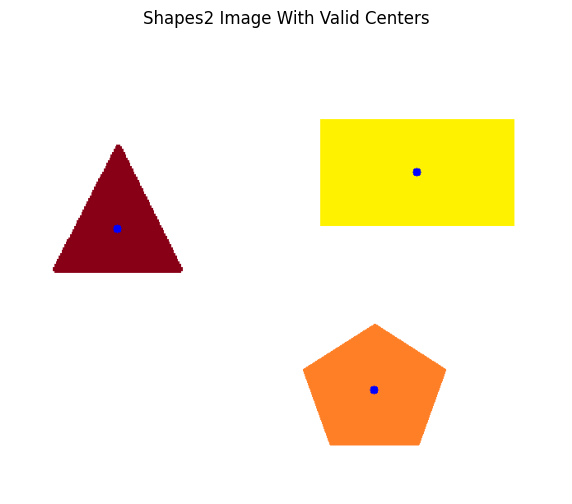

In [6]:
shapes2_image = cv2.imread(shapes2_path)
if shapes2_image is None:
  raise ValueError("Shapes2 Image Not Found")

shapes2_gray = cv2.cvtColor(shapes2_image, cv2.COLOR_BGR2GRAY)
_, shapes2_binary = cv2.threshold(shapes2_gray, 245, 255, cv2.THRESH_BINARY_INV)

shapes2_contours, shapes2_hierarchy = cv2.findContours(shapes2_binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

valid_centers = []
center_image = shapes2_image.copy()

for contour_id, contour in enumerate(shapes2_contours):
  moments = cv2.moments(contour)

  if moments['m00'] != 0:
    cx = int(moments['m10'] / moments['m00'])
    cy = int(moments['m01'] / moments['m00'])
    valid_centers.append((contour_id, cx, cy))

    cv2.circle(center_image, (cx, cy), 5, (255, 0, 0), -1)

print('Contours With Valid Centers:', len(valid_centers))

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(center_image, cv2.COLOR_BGR2RGB))
plt.title('Shapes2 Image With Valid Centers')
plt.axis('off')
plt.show()

Contour 1 Area: 30315.0
Contour 2 Area: 17775.0
Contour 3 Area: 12794.5


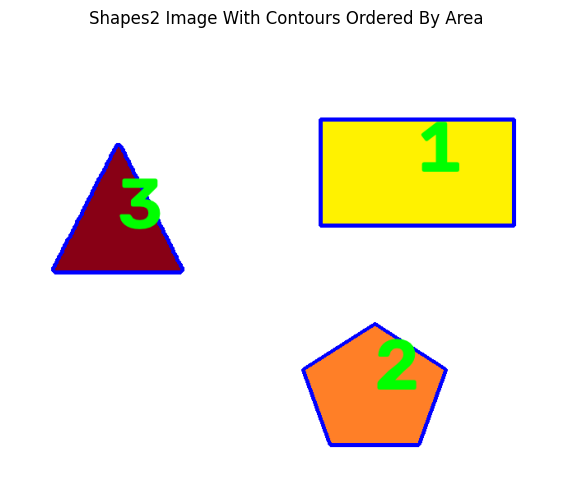

In [9]:
def get_contour_areas(Contours):
  areas = []

  for contour in Contours:
    area = cv2.contourArea(contour)
    areas.append(area)
  return areas

sorted_shapes2_contours = sorted(shapes2_contours, key=cv2.contourArea, reverse=True)

areas_image = shapes2_image.copy()

for order, contour in enumerate(sorted_shapes2_contours, start=1):
  moments = cv2.moments(contour)
  if moments['m00'] == 0:
    continue

  cx = int(moments['m10'] / moments['m00'])
  cy = int(moments['m01'] / moments['m00'])

  cv2.drawContours(areas_image, [contour], -1, (255, 0, 0), 3)
  cv2.putText(areas_image, str(order), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 3, (0, 255, 0), 3)

  print(f'Contour {order} Area: {cv2.contourArea(contour)}')

plt.figure(figsize=(8, 6))

plt.imshow(cv2.cvtColor(areas_image, cv2.COLOR_BGR2RGB))
plt.title('Shapes2 Image With Contours Ordered By Area')
plt.axis('off')

plt.show()

Sorted Balloon Contour Areas:
[11060.0, 3408.5, 3133.5, 1491.5, 337.5]


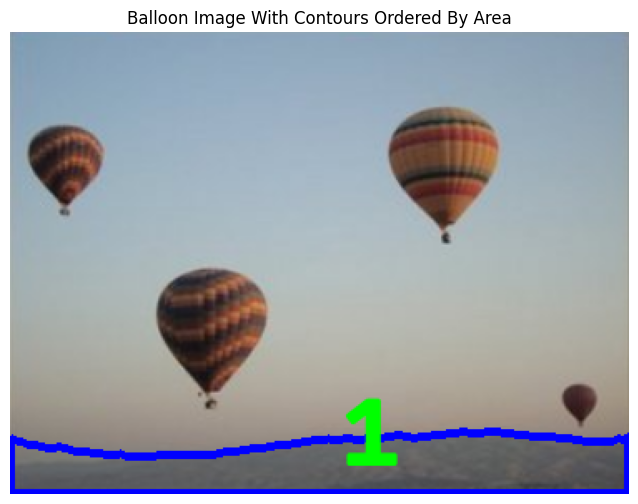

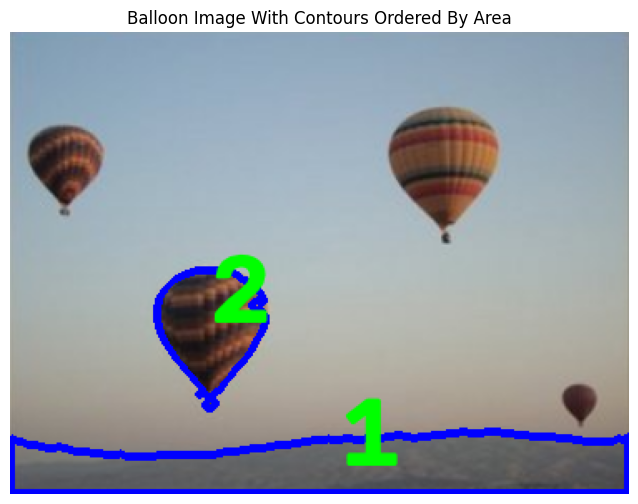

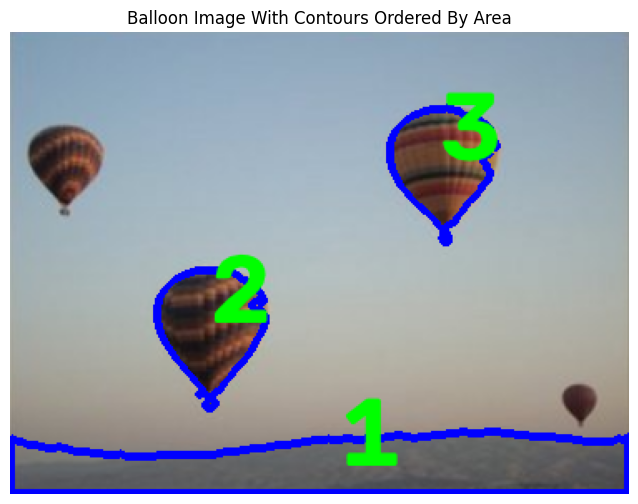

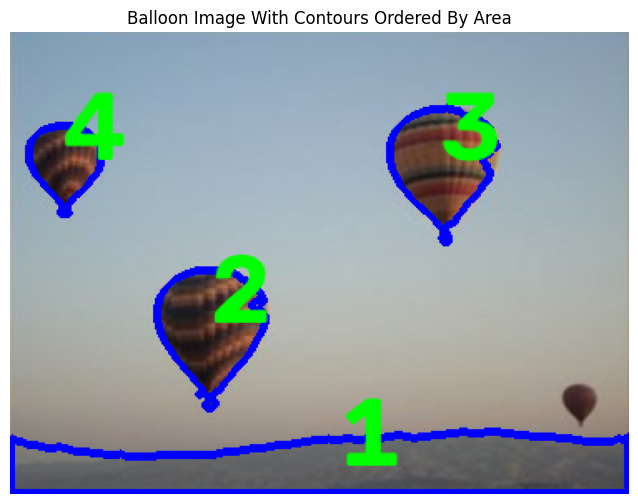

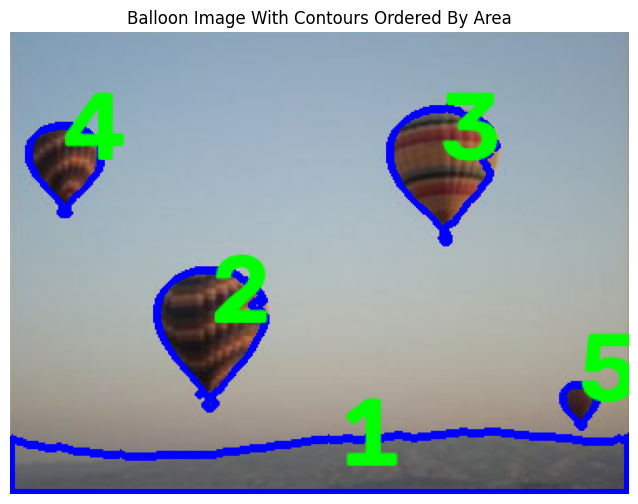

In [11]:
balloon_image = cv2.imread(balloon_path)
if balloon_image is None:
  raise ValueError("Balloon Image Not Found")

balloon_gray = cv2.cvtColor(balloon_image, cv2.COLOR_BGR2GRAY)

_, balloon_binary = cv2.threshold(balloon_gray, 127, 255, cv2.THRESH_BINARY_INV)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5), (2, 2))

balloon_closed = cv2.morphologyEx(balloon_binary, cv2.MORPH_CLOSE, kernel)

balloon_contours, ballon_hierarchy = cv2.findContours(balloon_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

sorted_balloon_contours = sorted(balloon_contours, key=cv2.contourArea, reverse=True)

balloon_areas = get_contour_areas(sorted_balloon_contours)

print('Sorted Balloon Contour Areas:')
print(balloon_areas)

balloon_result = balloon_image.copy()

for order, contour in enumerate(sorted_balloon_contours, start=1):
  moments = cv2.moments(contour)
  if moments['m00'] == 0:
    continue

  cx = int(moments['m10'] / moments['m00'])
  cy = int(moments['m01'] / moments['m00'])

  cv2.drawContours(balloon_result, [contour], -1, (255, 0, 0), 3)

  cv2.putText(balloon_result, str(order), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 3)

  plt.figure(figsize=(8, 6))

  plt.imshow(cv2.cvtColor(balloon_result, cv2.COLOR_BGR2RGB))
  plt.title('Balloon Image With Contours Ordered By Area')
  plt.axis('off')

  plt.show()

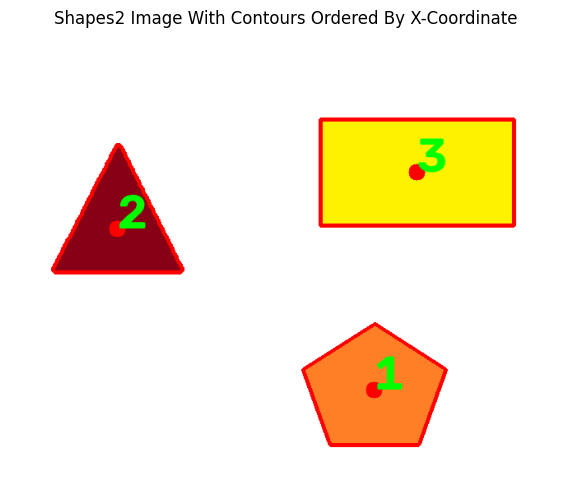

In [12]:
def contour_x_coordinate(contour):
  moments = cv2.moments(contour)
  if moments['m00'] == 0:
    return float('inf')
  return int(moments['m10'] / moments['m00'])

def mark_contours_center(image, contours):
  moments = cv2.moments(contours)
  if moments['m00'] == 0:
    return image

  cx = int(moments['m10'] / moments['m00'])
  cy = int(moments['m01'] / moments['m00'])

  cv2.circle(image, (cx, cy), 10, (0, 0, 255), -1)
  return image

left_to_right_image = shapes2_image.copy()
for order, contour in enumerate(shapes2_contours, start=1):
  mark_contours_center(left_to_right_image, contour)

  moments = cv2.moments(contour)
  if moments['m00'] == 0:
    continue

  cx = int(moments['m10'] / moments['m00'])
  cy = int(moments['m01'] / moments['m00'])

  cv2.drawContours(left_to_right_image, [contour], -1, (0, 0, 255), 3)

  cv2.putText(left_to_right_image, str(order), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 2, (0, 255, 0), 3)

plt.figure(figsize=(8, 6))

plt.imshow(cv2.cvtColor(left_to_right_image, cv2.COLOR_BGR2RGB))
plt.title('Shapes2 Image With Contours Ordered By X-Coordinate')
plt.axis('off')

plt.show()

In [13]:
output_images = {
    'shapes2_image': shapes2_image,
    'shapes2_gray': shapes2_gray,
    'shapes2_binary': shapes2_binary,
    'balloon_image': balloon_image
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename + '.png'
  cv2.imwrite(filename + '.png', output_image)
  print(f'Saved {filename} to {output_path}')
  files.download(output_path)
  print(f'Downloaded {filename} to {output_path}')

Saved shapes2_image to /content/shapes2_image.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded shapes2_image to /content/shapes2_image.png
Saved shapes2_gray to /content/shapes2_gray.png


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloaded shapes2_binary to /content/shapes2_binary.png
Saved balloon_image to /content/balloon_image.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded balloon_image to /content/balloon_image.png
